# AoA-only baseline



## Purpose

Measure how much of `cl`, `cd`, and `cm` can be predicted from the average AoA trend alone. The validation set comes from the official geometry split and is used only for evaluation.


In [1]:
import platform
from pathlib import Path

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.metrics import r2_score

project_dir = Path.cwd()
if not (project_dir / "data" / "prepared").is_dir():
    project_dir = project_dir.parent
assert (project_dir / "data" / "prepared").is_dir(), "Project root not found"

prepared_dir = project_dir / "data" / "prepared"
results_dir = project_dir / "results"
models_dir = results_dir / "models"
train_path = prepared_dir / "train.csv"
validation_path = prepared_dir / "validation.csv"
predictions_path = results_dir / "predictions.csv"
metrics_path = results_dir / "validation_metrics.csv"
model_path = models_dir / "aoa_only.joblib"

model_name = "aoa_only"
target_columns = ["cl", "cd", "cm"]
identifier_columns = ["case_id", "GeoID", "AoA", "split"]
load_columns = [*identifier_columns, *target_columns]
expected_aoas = [4, 6, 8, 10, 12, 14, 16, 18, 20, 22]
expected_rows = {"train": 1260, "validation": 180}
expected_geometries = {"train": 126, "validation": 18}
prediction_columns = [
    "case_id", "GeoID", "AoA", "split", "model", "target",
    "actual", "predicted", "error", "absolute_error", "squared_error",
]
metric_columns = [
    "model", "target", "scope", "AoA", "n_rows",
    "n_geometries", "MAE", "RMSE", "R2",
]

print(
    f"Python {platform.python_version()} | pandas {pd.__version__} | "
    f"scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__}"
)
print("Model input: AoA | Targets:", target_columns)

Python 3.10.20 | pandas 2.3.3 | scikit-learn 1.7.2 | matplotlib 3.10.9
Model input: AoA | Targets: ['cl', 'cd', 'cm']



## Load prepared data

Load only identifiers, AoA, and targets.


In [2]:
for path in [train_path, validation_path]:
    header = pd.read_csv(path, nrows=0).columns.tolist()
    assert set(load_columns).issubset(header), f"Required columns missing from {path.name}"

train = pd.read_csv(train_path, usecols=load_columns, dtype={"GeoID": "string"})
validation = pd.read_csv(validation_path, usecols=load_columns, dtype={"GeoID": "string"})

for split_name, frame in [("train", train), ("validation", validation)]:
    assert len(frame) == expected_rows[split_name]
    assert frame["GeoID"].nunique() == expected_geometries[split_name]
    assert frame["split"].eq(split_name).all()
    assert frame.notna().all().all()
    assert frame["case_id"].is_unique
    assert not frame.duplicated(["GeoID", "AoA"]).any()
    assert sorted(frame["AoA"].unique().tolist()) == expected_aoas
    assert frame.groupby("GeoID")["AoA"].apply(
        lambda values: sorted(values.tolist()) == expected_aoas
    ).all()
    assert all(pd.api.types.is_numeric_dtype(frame[column]) for column in ["AoA", *target_columns])

assert set(train["GeoID"]).isdisjoint(validation["GeoID"])

pd.DataFrame(
    [
        {
            "split": name,
            "rows": len(frame),
            "geometries": frame["GeoID"].nunique(),
            "AoAs": frame["AoA"].nunique(),
            "missing_values": int(frame.isna().sum().sum()),
        }
        for name, frame in [("train", train), ("validation", validation)]
    ]
)

,split,rows,geometries,AoAs,missing_values
0,train,1260,126,10,0
1,validation,180,18,10,0



## Model setup

For each AoA and target, the model calculates the mean target value from the training geometries. A validation case receives the training mean corresponding to its AoA. The model has no geometry inputs, preprocessing, hyperparameters, or cross-validation. Error is `predicted - actual`.

### Model equation

For each target separately:

$$
\hat y(a)=\frac{1}{N_a}\sum_{i:\,\mathrm{AoA}_i=a}y_i
$$

Here, $a$ is an angle of attack, $N_a$ is the number of training cases at that angle, and $y_i$ is the training target value.



## Fit the selected configuration

In [3]:
aoa_means = train.groupby("AoA", sort=True)[target_columns].mean().reindex(expected_aoas)
assert aoa_means.notna().all().all()

aoa_model = {
    "model": model_name,
    "input": "AoA",
    "ordered_aoas": expected_aoas,
    "targets": target_columns,
    "training_mean_lookup": {
        target: {int(aoa): float(value) for aoa, value in aoa_means[target].items()}
        for target in target_columns
    },
}

models_dir.mkdir(parents=True, exist_ok=True)
joblib.dump(aoa_model, model_path)
aoa_means.rename_axis("AoA").reset_index()

reloaded_aoa_model = joblib.load(model_path)
assert reloaded_aoa_model == aoa_model


,AoA,cl,cd,cm
0,4,1.186631,0.109494,-0.134140
1,6,1.383102,0.130912,-0.187362
2,8,1.575952,0.157027,-0.241663
3,10,1.758844,0.186646,-0.293430
4,12,1.917255,0.218590,-0.334335
5,14,2.023777,0.253594,-0.351857
6,16,2.023398,0.309339,-0.316787
7,18,1.903923,0.381462,-0.386616
8,20,1.849745,0.453152,-0.486591
9,22,1.818050,0.523909,-0.568903



## Validation metrics



In [4]:
def predict_from_lookup(frame, fitted_lookup):
    return pd.DataFrame(
        {
            target: frame["AoA"].map(fitted_lookup["training_mean_lookup"][target])
            for target in fitted_lookup["targets"]
        },
        index=frame.index,
    )


def to_long_predictions(frame, predicted):
    parts = []
    for target in target_columns:
        part = frame[identifier_columns].copy()
        part["model"] = model_name
        part["target"] = target
        part["actual"] = frame[target].to_numpy()
        part["predicted"] = predicted[target].to_numpy()
        part["error"] = part["predicted"] - part["actual"]
        part["absolute_error"] = part["error"].abs()
        part["squared_error"] = part["error"].pow(2)
        parts.append(part[prediction_columns])
    return pd.concat(parts, ignore_index=True)


train_predicted = predict_from_lookup(train, aoa_model)
validation_predicted = predict_from_lookup(validation, aoa_model)
notebook_predictions = pd.concat(
    [
        to_long_predictions(train, train_predicted),
        to_long_predictions(validation, validation_predicted),
    ],
    ignore_index=True,
)
assert len(notebook_predictions) == 4320
assert notebook_predictions.groupby("split").size().to_dict() == {"train": 3780, "validation": 540}
assert notebook_predictions[["case_id", "model", "target"]].duplicated().sum() == 0

results_dir.mkdir(parents=True, exist_ok=True)
if predictions_path.exists():
    existing_predictions = pd.read_csv(predictions_path, dtype={"GeoID": "string"})
    assert list(existing_predictions.columns) == prediction_columns
    preserved_predictions = existing_predictions.loc[existing_predictions["model"].ne(model_name)]
    predictions_to_save = pd.concat([preserved_predictions, notebook_predictions], ignore_index=True)
else:
    predictions_to_save = notebook_predictions

assert not predictions_to_save.duplicated(["case_id", "split", "model", "target"]).any()
predictions_to_save.to_csv(predictions_path, index=False, lineterminator="\n")
saved_predictions = pd.read_csv(predictions_path, dtype={"GeoID": "string"}, float_precision="round_trip")
saved_model_predictions = saved_predictions.loc[saved_predictions["model"].eq(model_name)].reset_index(drop=True)
saved_validation_predictions = saved_model_predictions.loc[
    saved_model_predictions["split"].eq("validation")
].reset_index(drop=True)

saved_model_predictions.groupby(["split", "target"], sort=False).size().rename("rows").to_frame()

rows
split      target      
train      cl      1260
           cd      1260
           cm      1260
validation cl       180
           cd       180
           cm       180

In [5]:
def metric_row(rows, target, scope, aoa=pd.NA):
    return {
        "model": model_name,
        "target": target,
        "scope": scope,
        "AoA": aoa,
        "n_rows": len(rows),
        "n_geometries": rows["GeoID"].nunique(),
        "MAE": rows["absolute_error"].mean(),
        "RMSE": np.sqrt(rows["squared_error"].mean()),
        "R2": r2_score(rows["actual"], rows["predicted"]),
    }


def build_validation_metrics(validation_rows):
    rows = []
    for target in target_columns:
        target_rows = validation_rows.loc[validation_rows["target"].eq(target)]
        rows.append(metric_row(target_rows, target, "overall"))
        for aoa in expected_aoas:
            aoa_rows = target_rows.loc[target_rows["AoA"].eq(aoa)]
            rows.append(metric_row(aoa_rows, target, "per_aoa", aoa))
    result = pd.DataFrame(rows, columns=metric_columns)
    result["AoA"] = pd.array(result["AoA"], dtype="Int64")
    return result


notebook_metrics = build_validation_metrics(saved_validation_predictions)
assert len(notebook_metrics) == 33
assert notebook_metrics["scope"].value_counts().to_dict() == {"per_aoa": 30, "overall": 3}
assert (notebook_metrics.loc[notebook_metrics["scope"].eq("per_aoa"), "n_rows"] == 18).all()

if metrics_path.exists():
    existing_metrics = pd.read_csv(metrics_path)
    assert list(existing_metrics.columns) == metric_columns
    preserved_metrics = existing_metrics.loc[existing_metrics["model"].ne(model_name)]
    metrics_to_save = pd.concat([preserved_metrics, notebook_metrics], ignore_index=True)
else:
    metrics_to_save = notebook_metrics

assert not metrics_to_save.duplicated(["model", "target", "scope", "AoA"]).any()
metrics_to_save.to_csv(metrics_path, index=False, lineterminator="\n")

display(notebook_metrics.loc[notebook_metrics["scope"].eq("overall")].reset_index(drop=True))
display(
    notebook_metrics.loc[notebook_metrics["scope"].eq("per_aoa")]
    .pivot(index="AoA", columns="target", values="MAE")
    .rename_axis(columns="validation MAE")
)

C:\Users\purus\AppData\Local\Temp\ipykernel_51504\265594607.py:37: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  metrics_to_save = pd.concat([preserved_metrics, notebook_metrics], ignore_index=True)


,model,target,scope,AoA,n_rows,n_geometries,MAE,RMSE,R2
0,aoa_only,cl,overall,<NA>,180,18,0.142320,0.184291,0.696275
1,aoa_only,cd,overall,<NA>,180,18,0.029068,0.039513,0.908863
2,aoa_only,cm,overall,<NA>,180,18,0.117285,0.156525,0.451207


validation MAE,cd,cl,cm
AoA,,,
4,0.016525,0.105930,0.066825
6,0.018019,0.104695,0.068204
8,0.019686,0.103935,0.068543
10,0.020934,0.103529,0.073080
12,0.021555,0.101748,0.073562
14,0.020690,0.105222,0.072268
16,0.025269,0.157300,0.098209
18,0.036953,0.193505,0.191050
20,0.050829,0.228348,0.217572


## Validation plots

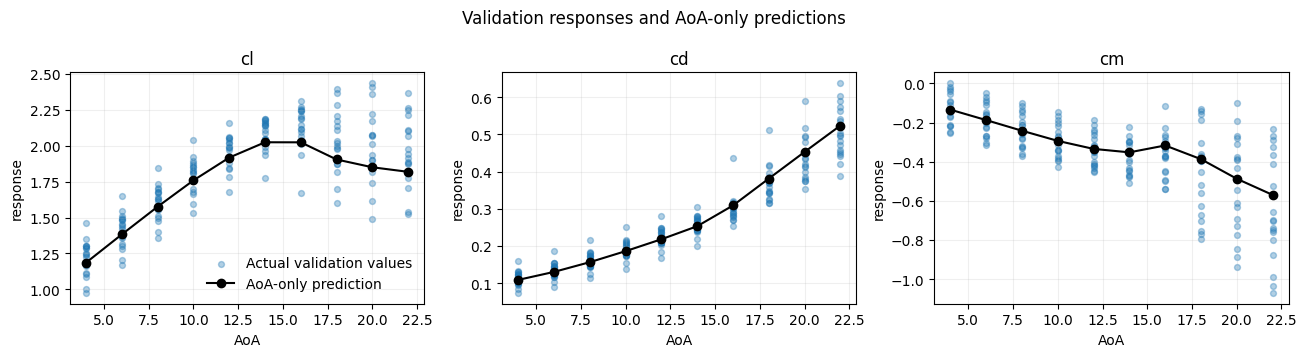

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, target in zip(axes, target_columns):
    ax.scatter(validation["AoA"], validation[target], s=18, alpha=0.35, label="Actual validation values")
    ax.plot(expected_aoas, aoa_means[target], color="black", marker="o", label="AoA-only prediction")
    ax.set(title=target, xlabel="AoA", ylabel="response")
    ax.grid(alpha=0.2)
axes[0].legend(frameon=False)
fig.suptitle("Validation responses and AoA-only predictions")
fig.tight_layout()
plt.show()

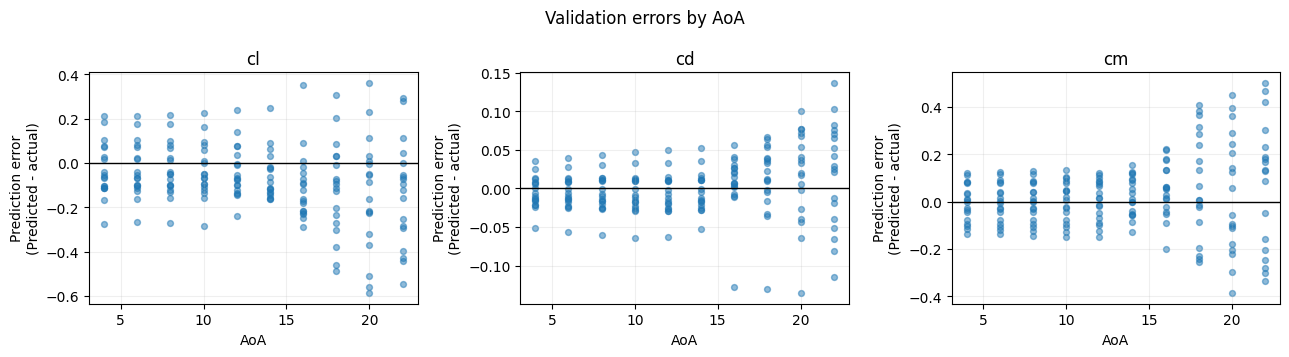

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, target in zip(axes, target_columns):
    rows = saved_validation_predictions.loc[saved_validation_predictions["target"].eq(target)]
    ax.scatter(rows["AoA"], rows["error"], s=18, alpha=0.5)
    ax.axhline(0.0, color="black", linewidth=1)
    ax.set(title=target, xlabel="AoA", ylabel="Prediction error\n(Predicted - actual)")
    ax.grid(alpha=0.2)
fig.suptitle("Validation errors by AoA")
fig.tight_layout()
plt.show()


## Short conclusion

The model captures the average response trend with AoA, but every geometry at the same AoA receives the same prediction. A negative per-AoA R² means the training-set AoA mean performs worse for that validation group and this is expected when the model has no geometry information. This is a reference baseline. 



## Save results

The notebook writes `results/predictions.csv`, `results/validation_metrics.csv`, and `results/models/aoa_only.joblib`. Reruns replace only `aoa_only` rows.
